In [16]:
# Änderungen:
# Vorläufiges Splitten nach Hotel bei Modellen (nur Entscheidungsbaum), vielleicht zu viel und unnötig
# Handhabung Vorhersage falls Splitten am Besten

# Weitere Features in features() aufgenommen





# TODO:
# Mehr Datenanalyse, Plots usw. (zB Entwicklung vorlaufzeit / stornierungsrate)
# Land und agentur durch stoniert in Risikogruppen einteilen und map erstellen (dictonary)
# Gurobi verstehen, dokumentieren
# Modelle Hyperparamater anpassen

#       Hotels getrennt
#       Vorlaufzeit = 0 als Feature (vor Ort) als extra Spalte
#       Frühere Buchung / Stornierung in Prozent

# Erwachsene / Kinder / Babys OHE
#       Anmerkung: Da wir überwiegend Bäume (und diese auch am Besten sein werden) verwenden, macht das dann noch Sinn, schließlich würden
#           Splits wie Kinder < 3 nicht mehr funktionieren?
#       Und dass es keinen linearen Zusammenhang gibt, müssten Bäume ja auch von selbst lernen können?
#       Würde diese numerisch lassen

# zimmer umgebucht
# marktsegment == buchungskanal

# (1) Betrachtung der Daten

In [17]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

CV = 2  # GridSearchCV: Anzahl Kreuzvalidierungen
VERBOSE = 1  # GridSearchCV: Informationsgehalt der Ausgaben
N_JOBS = 4

df_train = pd.read_csv("data/buchungen.csv")
df_test = pd.read_csv("data/buchungen_test.csv")  # Test-Datensatz ohne Storniert-Status

display(df_train.dtypes)  # Ausgabe der Spalten und deren jeweiligen Datentyp
display(df_train)

hotel_typ                          str
storniert                        int64
anreisedatum                       str
vorlaufzeit_tage                 int64
naechte_wochenende               int64
naechte_wochentag                int64
erwachsene                       int64
kinder                         float64
babys                            int64
verpflegung                        str
herkunftsland                      str
marktsegment                       str
buchungskanal                      str
stammgast                        int64
frueh_stornierungen              int64
frueh_buchungen_eingehalten      int64
gebuchter_zimmertyp                str
zugewiesener_zimmertyp             str
buchungsaenderungen              int64
anzahlungsart                      str
agentur_id                     float64
warteliste_tage                  int64
kundentyp                          str
durchschn_tagespreis           float64
parkplaetze_benoetigt            int64
anzahl_sonderwuensche    

,hotel_typ,storniert,anreisedatum,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,...,buchungsaenderungen,anzahlungsart,agentur_id,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,reservierungsstatus,reservierungsstatus_datum
0,Ferienhotel,0,2015-07-01,340,0,0,2,0.0,0,Frühstück,...,3,Ohne Anzahlung,NaN,0,Einzelbucher,0.61,0,0,Ausgecheckt,2015-07-01
1,Ferienhotel,0,2015-07-01,738,0,0,2,0.0,0,Frühstück,...,4,Ohne Anzahlung,NaN,0,Einzelbucher,0.97,0,0,Ausgecheckt,2015-07-01
2,Ferienhotel,0,2015-07-01,14,0,1,1,0.0,0,Frühstück,...,0,Ohne Anzahlung,304.0,0,Einzelbucher,75.98,0,0,Ausgecheckt,2015-07-02
3,Ferienhotel,0,2015-07-01,14,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,240.0,0,Einzelbucher,98.18,0,1,Ausgecheckt,2015-07-03
4,Ferienhotel,0,2015-07-01,0,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,NaN,0,Einzelbucher,106.52,0,0,Ausgecheckt,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95507,Stadthotel,0,2017-08-30,22,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,95.82,0,2,Ausgecheckt,2017-09-06
95508,Stadthotel,0,2017-08-30,21,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,96.24,0,0,Ausgecheckt,2017-09-06
95509,Stadthotel,0,2017-08-31,32,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,9.0,0,Einzelbucher,157.43,0,4,Ausgecheckt,2017-09-07
95510,Stadthotel,0,2017-08-31,110,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,89.0,0,Einzelbucher,104.14,0,0,Ausgecheckt,2017-09-07


Stornierungsraten:
Gesamt:                  37.04 %
Ferienhotel:             28.05 %
Stadthotel:              41.56 %
Buchungen vor Ort:       7.75 %
Kurzfristige Buchungen:  8.89 %


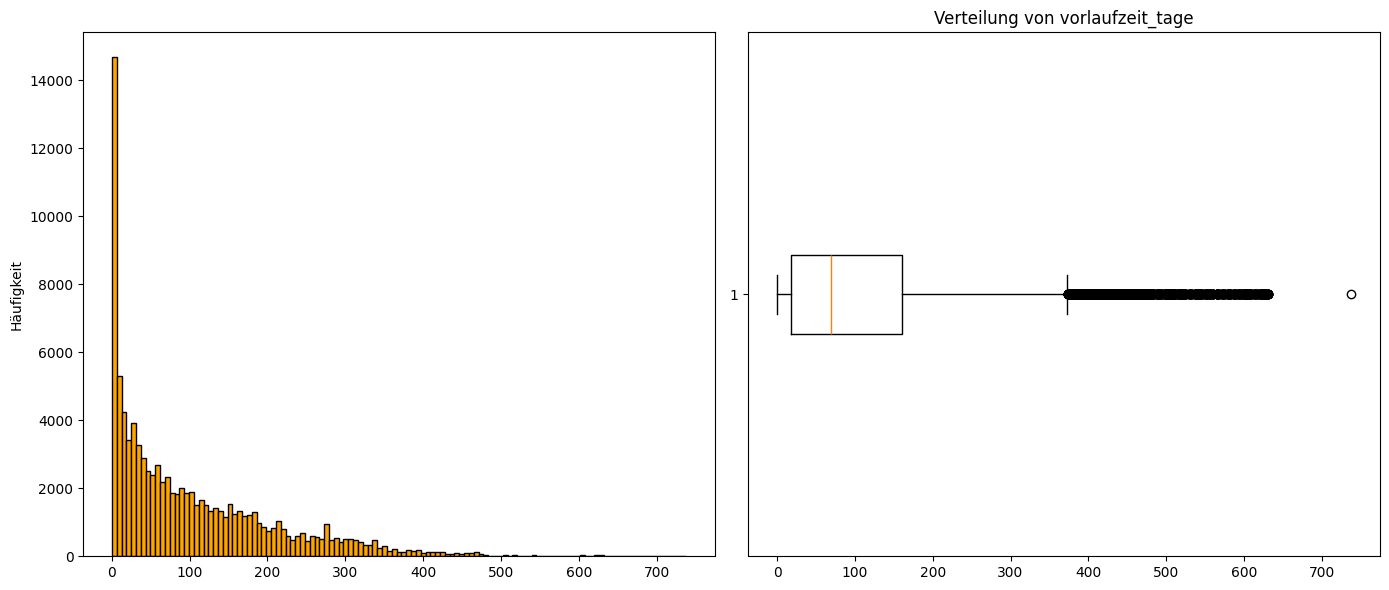

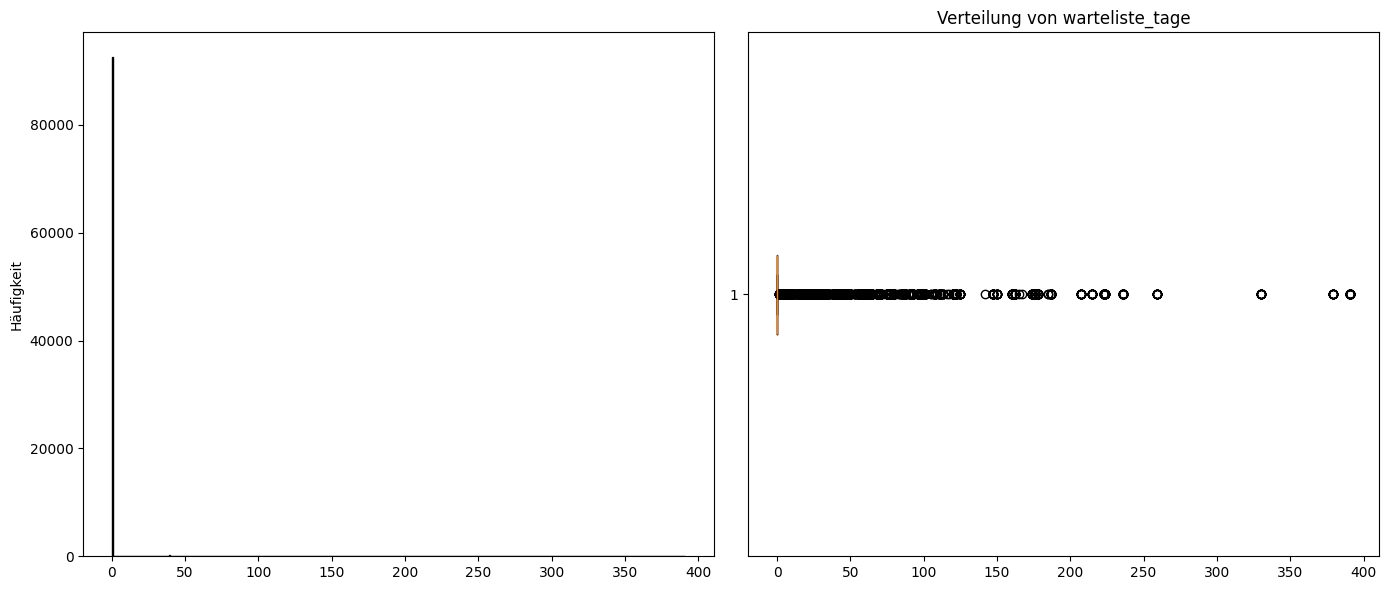

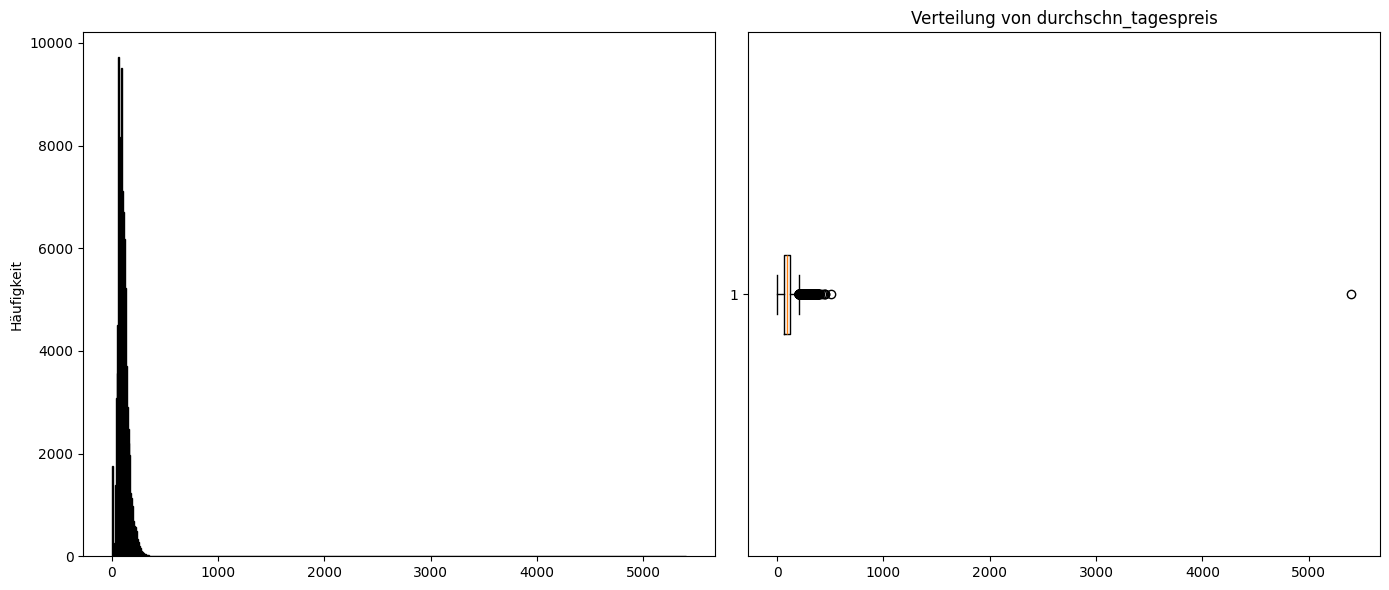

In [18]:
df = df_train.copy()

cancel_rate = float(df.loc[df["storniert"] == 1]["storniert"].count() / df["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Ferienhotel"]
cancel_rate_holiday = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Stadthotel"]
cancel_rate_city = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["vorlaufzeit_tage"] == 0]
cancel_rate_vorlaufzeit = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["vorlaufzeit_tage"] < 5]
cancel_rate_recent_resv = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

print(
    f"Stornierungsraten:\n"
    f"Gesamt:                  {cancel_rate:.2f} %\n"
    f"Ferienhotel:             {cancel_rate_holiday:.2f} %\n"
    f"Stadthotel:              {cancel_rate_city:.2f} %\n"
    f"Buchungen vor Ort:       {cancel_rate_vorlaufzeit:.2f} %\n"
    f"Kurzfristige Buchungen:  {cancel_rate_recent_resv:.2f} %")

# TODO: Auswahl von Spalten zum plotten
# for column in df.select_dtypes(include=np.number).columns.drop(["storniert", "stammgast", "agentur_id"]):
for column in ["vorlaufzeit_tage", "warteliste_tage", "durchschn_tagespreis"]:
    _, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].hist(df[column].dropna(), bins="auto", color="orange", edgecolor="black")
    axes[0].set_ylabel("Häufigkeit")

    axes[1].boxplot(df[column].dropna(), vert=False)

    plt.title(f"Verteilung von {column}")
    plt.tight_layout()
    plt.show()

# (2 / 3) Vorverarbeitung und Feature Engineering

In [19]:
# Anzahl Feiertage im Buchungszeitraum
df_holidays = pd.read_csv("data/portugal_feiertage.csv")
df_holidays["datum"] = pd.to_datetime(df_holidays["datum"])
df_holidays = df_holidays.set_index("datum")


def map_holidays(df: pd.DataFrame) -> pd.DataFrame:
    """Berechnet die Anzahl an Feiertage innerhalb eines Buchungszeitraumes als neues Feature."""
    df = df.copy()
    df["abreisedatum"] = df["anreisedatum"] + pd.to_timedelta((df["naechte_wochenende"] + df["naechte_wochentag"]), unit="D")

    df["anzahl_feiertage"] = 0
    for d in df_holidays.index:
        df["anzahl_feiertage"] += ((df["anreisedatum"] <= d) & (df["abreisedatum"] >= d)).astype(int)

    return df.drop(columns=["abreisedatum"])

In [20]:
import country_converter as coco

# Manche Einträge kann country-converter nicht zuordnen
# Die Tabelle: https://de.wikipedia.org/wiki/ISO-3166-1-Kodierliste
# hat eine vollständige Liste und führt auch veraltete Codes auf
MANUAL_CONTINENT_MAPPING = {
    "TMP": "Asia",  # Osttimor (veraltet), aktueller Code: TLS
}


# TODO: Features Mapping für Test-Set
def add_country_features(df: pd.DataFrame) -> pd.DataFrame:
    """Ersetzt "herkunftsland" durch zwei neue Features.

    "herkunftskontinent": Kontinent des Herkunftslandes.
    "aus_portugal":       1 wenn Herkunftsland Portugal (PRT), sonst 0.
    """
    cc = coco.CountryConverter()
    df = df.copy()

    # Binäres Feature: Gast kommt aus Portugal
    # TODO: Auswahl weiterer Länder
    df["aus_portugal"] = (df["herkunftsland"] == "PRT").astype(bool)

    def map_continent(code):
        if pd.isna(code):
            return "Unbekannt"
        if code in MANUAL_CONTINENT_MAPPING:
            return MANUAL_CONTINENT_MAPPING[code]
        return cc.convert(code, to="continent")

    df["herkunftskontinent"] = df["herkunftsland"].apply(map_continent)
    return df.drop(columns=["herkunftsland"])

In [21]:
def features(df: pd.DataFrame, drop: list | None = None) -> pd.DataFrame:
    """Generiert oder transformiert neue Features."""
    drop = [] if drop is None else drop
    df = df.copy()

    df["anreisedatum"] = pd.to_datetime(df["anreisedatum"])
    df["stammgast"] = df["stammgast"].astype(str)  # Stammgast ist kategorisch
    df["agentur_id"] = df["agentur_id"].astype(str)  # Agenturen sind kategorisch

    # Buchungen direkt vor Ort haben eine geringe Stornierungsrate
    # TODO: Ist dies tatsächlich sinnvoll, wenn z.B. 0 < vorlaufzeit_tage < 5 die gleiche Rate hat (+1%)
    # Damit wäre "Buchung vor Ort" kein Sonderfall, und damit redundant?
    # Vielleicht eher "kurzfristige_buchungen" als Feature, mit vorlaufzeit < 10 oder ähnlich
    df["buchung_vor_ort"] = (df["vorlaufzeit_tage"] == 0).astype(int)

    # Additive Glättung verhindert unnütze extreme Raten (wie 1 Stornierung/1 Gesamt => 100%)
    df["frueh_stornierungsrate"] = (df["frueh_stornierungen"] + 2) / (df["frueh_stornierungen"] + df["frueh_buchungen_eingehalten"] + 2 * 2)

    df = map_holidays(df)
    # df = add_country_features(df)  # TODO: Ersetzen durch Stonierungsrate nach Land, Einteilung nach Prozenten Verteilung ausgeben lassen

    return df.drop(columns=[*drop, "anreisedatum", "agentur_id", "frueh_stornierungen", "frueh_buchungen_eingehalten"])

In [22]:
from sklearn.model_selection import train_test_split

# Duplizierte Datenpunkte entfernen (hier vor dem Split)
print(f"Anzahl Duplikate: {df_train.duplicated().sum()}")
df_train = df_train.drop_duplicates()

# Entfernen von nicht relevanten Spalten
df_train = features(df_train, ["reservierungsstatus", "reservierungsstatus_datum"])

# Im Folgendem wird nur noch der Trainingsdatensatz betrachtet um Data Leakage zu vermeiden
X_train, X_valid, y_train, y_valid = train_test_split(
    df_train.drop(columns=["storniert"]),
    df_train["storniert"],
    test_size=0.2,
    random_state=42,
)

categorical = X_train.select_dtypes(exclude=np.number).columns
numerical = X_train.select_dtypes(include=np.number).columns

Anzahl Duplikate: 286


In [23]:
# Ergebnis von Transformation der Länder prüfen
print(
    "Verteilung Kontinente (Trainingsdaten):\n"
    # f"{X_train['herkunftskontinent'].value_counts()}\n\n"
    f"Anteil Gäste aus Portugal: "
    # f"{X_train['aus_portugal'].astype(int).mean():.1%}\n"
)

# Ausgabe kategorischer Features
print(f"Kategorische Features ({len(categorical)}):\n")
for col in categorical:
    n_unique = X_train[col].nunique()
    print(f"{col:25} {n_unique:5} eindeutige Werte")

display("Trainingsdatensatz (kategorische Features):", X_train[categorical])

# Spalten die fehlende Werte enthalten ausgeben
missing = X_train.isna().sum()
display("Spalten mit fehlenden Werten:", missing[missing > 0])

# Ausreißern veranschaulichen
display(
    "Verteilung numerischer Features:",
    X_train.select_dtypes(include=np.number).describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999]),
)

Verteilung Kontinente (Trainingsdaten):
Anteil Gäste aus Portugal: 
Kategorische Features (10):

hotel_typ                     2 eindeutige Werte
verpflegung                   5 eindeutige Werte
herkunftsland               168 eindeutige Werte
marktsegment                  8 eindeutige Werte
buchungskanal                 5 eindeutige Werte
stammgast                     2 eindeutige Werte
gebuchter_zimmertyp          10 eindeutige Werte
zugewiesener_zimmertyp       12 eindeutige Werte
anzahlungsart                 3 eindeutige Werte
kundentyp                     4 eindeutige Werte


'Trainingsdatensatz (kategorische Features):'

,hotel_typ,verpflegung,herkunftsland,marktsegment,buchungskanal,stammgast,gebuchter_zimmertyp,zugewiesener_zimmertyp,anzahlungsart,kundentyp
76374,Stadthotel,Frühstück,PRT,Online Reisebüro,Reisebüro,0,D,K,Ohne Anzahlung,Einzelbucher
66460,Stadthotel,Frühstück,PRT,Direktbuchung,Direkt,0,D,D,Ohne Anzahlung,Einzelbucher
82131,Stadthotel,Frühstück,FRA,Offline Reisebüro,Reisebüro,0,A,A,Ohne Anzahlung,Einzelbucher
44586,Stadthotel,Frühstück,GBR,Online Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,Einzelbucher
49014,Stadthotel,Frühstück,PRT,Direktbuchung,Direkt,0,A,A,Ohne Anzahlung,Einzelbucher
...,...,...,...,...,...,...,...,...,...,...
6277,Ferienhotel,Frühstück,MAR,Online Reisebüro,Reisebüro,0,G,G,Ohne Anzahlung,Einzelbucher
55072,Stadthotel,Frühstück,ESP,Online Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,Einzelbucher
77084,Stadthotel,Frühstück,PRT,Offline Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,Einzelbucher
860,Ferienhotel,Frühstück,ESP,Online Reisebüro,Reisebüro,0,D,E,Ohne Anzahlung,Einzelbucher


'Spalten mit fehlenden Werten:'

kinder             3
herkunftsland    300
dtype: int64

'Verteilung numerischer Features:'

,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,buchungsaenderungen,warteliste_tage,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,buchung_vor_ort,frueh_stornierungsrate,anzahl_feiertage
count,76180.000000,76180.000000,76180.000000,76180.000000,76177.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000
mean,103.834602,0.929942,2.498307,1.858112,0.103260,0.007981,0.220924,2.293712,101.953647,0.062930,0.574587,0.046495,0.499894,0.176424
std,106.767568,0.998556,1.911787,0.584068,0.397326,0.101392,0.655072,17.337603,51.788280,0.247444,0.794688,0.210556,0.044111,0.411521
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.055556,0.000000
5%,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,38.500000,0.000000,0.000000,0.000000,0.500000,0.000000
10%,3.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,50.609000,0.000000,0.000000,0.000000,0.500000,0.000000
25%,18.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,69.310000,0.000000,0.000000,0.000000,0.500000,0.000000
50%,69.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,94.470000,0.000000,0.000000,0.000000,0.500000,0.000000
75%,160.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,125.900000,0.000000,1.000000,0.000000,0.500000,0.000000
90%,264.100000,2.000000,5.000000,2.000000,0.000000,0.000000,1.000000,0.000000,164.211000,0.000000,2.000000,0.000000,0.500000,1.000000


'Korrelation der numerischen Features mit storniert:'

storniert                 1.000000
vorlaufzeit_tage          0.291703
frueh_stornierungsrate    0.237872
erwachsene                0.059906
warteliste_tage           0.051933
durchschn_tagespreis      0.044816
anzahl_feiertage          0.035741
naechte_wochentag         0.024607
kinder                    0.008338
naechte_wochenende        0.001288
babys                    -0.031539
buchung_vor_ort          -0.131794
buchungsaenderungen      -0.141515
parkplaetze_benoetigt    -0.194634
anzahl_sonderwuensche    -0.235324
Name: storniert, dtype: float64

'Korrelation der kategorischen Features mit storniert:'

storniert                         1.000000
anzahlungsart_Nicht erstattbar    0.478201
herkunftsland_PRT                 0.333968
marktsegment_Gruppen              0.219147
zugewiesener_zimmertyp_A          0.196030
                                    ...   
zugewiesener_zimmertyp_D         -0.129579
hotel_typ_Ferienhotel            -0.132513
buchungskanal_Direkt             -0.151186
marktsegment_Direktbuchung       -0.152973
anzahlungsart_Ohne Anzahlung     -0.474224
Name: storniert, Length: 221, dtype: float64

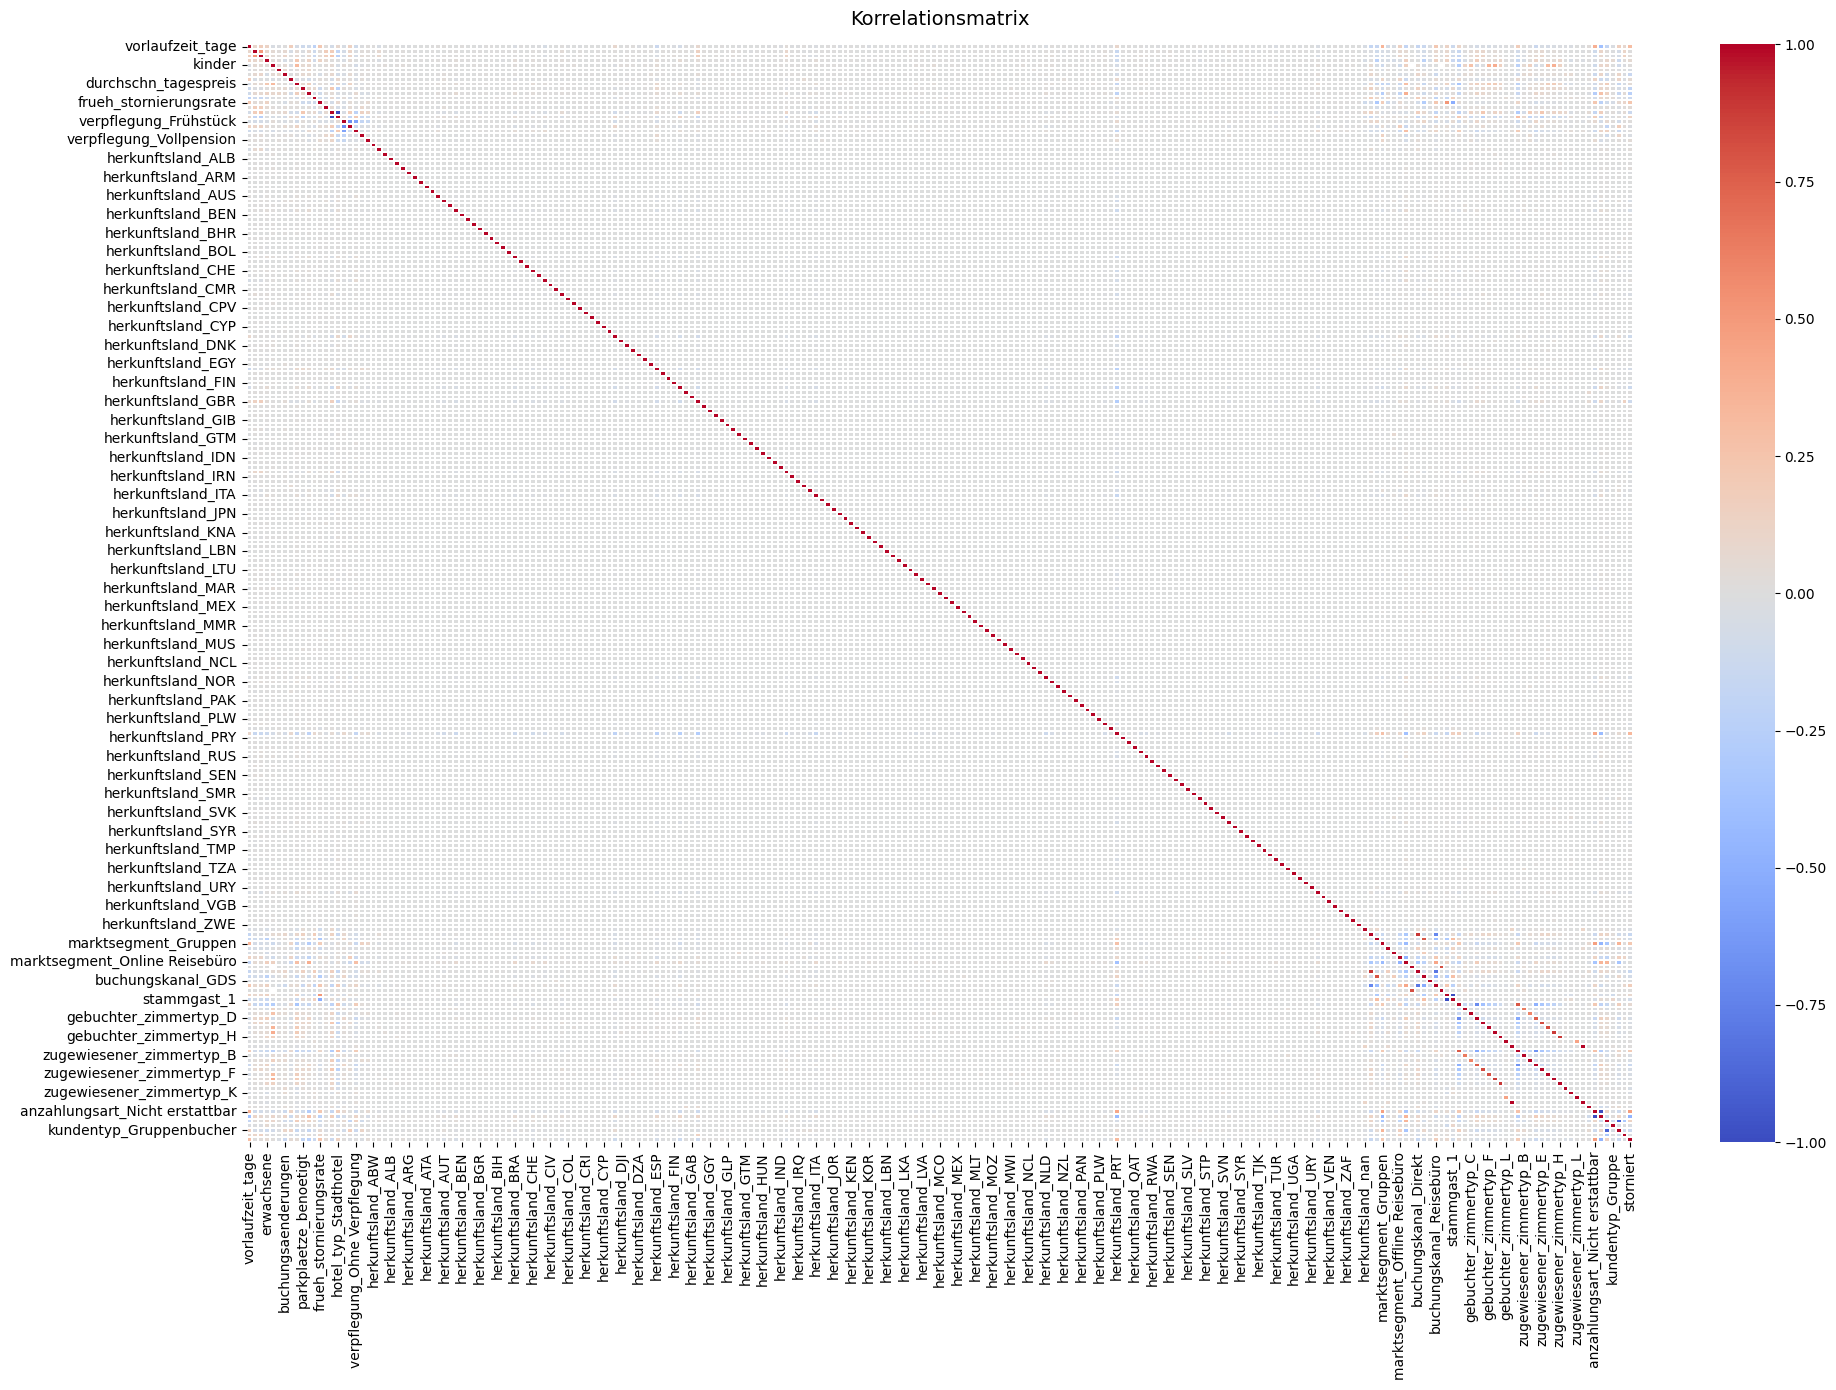

In [24]:
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder


def show_correlations(df: pd.DataFrame, target: pd.DataFrame, text: str) -> None:
    """Ausgabe der Korrelationen."""
    df_corr = df.copy()
    df_corr["storniert"] = target.copy()

    correlations = df_corr.corr()
    display(text, correlations["storniert"].sort_values(ascending=False))


show_correlations(X_train[numerical], y_train, "Korrelation der numerischen Features mit storniert:")

encoding = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# TODO: Entfernen nach Behandlung
# categorical = categorical.drop("agentur_id")  # TODO: Agentur in Risikogruppen unterteilen
df_encoded = encoding.fit_transform(X=X_train[categorical])
df_encoded = pd.DataFrame(df_encoded, columns=encoding.get_feature_names_out(), index=X_train.index)

show_correlations(df_encoded, y_train, "Korrelation der kategorischen Features mit storniert:")

# Korrelationsmatrix der Features
df_heatmap = pd.concat([X_train[numerical], df_encoded], axis=1)
df_heatmap["storniert"] = y_train

_, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    df_heatmap.corr(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot=False,
    ax=ax,
)
plt.title("Korrelationsmatrix", fontsize=14, pad=14)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def clip_numericals(X: np.ndarray) -> np.ndarray:
    """Behandlung von Ausreißern."""
    upper = np.percentile(X, 99, axis=0)

    return np.clip(X, 0, upper)


numerical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),  # Kinder (keine Angabe = keine Kinder)
        ("clip", FunctionTransformer(clip_numericals, validate=False)),
        ("scaler", StandardScaler()),  # Für logistische Regression
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Keine Angabe")),  # Herkunftsland und Agenturen
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical), ("cat", categorical_pipeline, categorical)])

# (4) Training der Modelle

In [26]:
import gurobipy as gp
from gurobipy import GRB


def optimize_threshold_gurobi(y_true: pd.Series, y_prob: pd.Series, df_features: pd.DataFrame) -> tuple[float, float]:
    """Minimiert Gesamtkosten und berechnet Schwellwert."""
    aufenthaltsdauer = df_features["naechte_wochenende"] + df_features["naechte_wochentag"]
    fn_kosten = (df_features["durchschn_tagespreis"] * aufenthaltsdauer * 0.9).values

    y = y_true.values
    p = y_prob
    N = len(y)

    env = gp.Env(empty=True)
    env.setParam("OutputFlag", 0)
    env.start()
    m = gp.Model("Threshold_Optimierung", env=env)

    t = m.addVar(vtype=GRB.CONTINUOUS, lb=0.0, ub=1.0, name="threshold")
    z = m.addVars(N, vtype=GRB.BINARY, name="z")

    M = 1.01
    eps = 1e-5

    for i in range(N):
        m.addConstr(p[i] - t >= -M * (1 - z[i]), name=f"lower_{i}")
        m.addConstr(p[i] - t <= M * z[i] - eps, name=f"upper_{i}")

    kosten = gp.LinExpr()
    for i in range(N):
        if y[i] == 0:
            kosten += 250.0 * z[i]
        else:
            kosten += fn_kosten[i] * (1 - z[i])

    m.setObjective(kosten, GRB.MINIMIZE)
    m.optimize()

    if m.status == GRB.OPTIMAL:
        return m.ObjVal, t.X
    raise ValueError("Gurobi konnte keine optimale Lösung finden.")

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import GridSearchCV


def show_metrics(y_true: pd.DataFrame, y_pred: pd.DataFrame, title: str = "") -> None:
    """Ausgabe der relevanten Metriken."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    print(
        f"{title}\n"
        f"Accuracy:             {accuracy_score(y_true, y_pred) * 100:.7f}\n"
        f"Precision:            {precision_score(y_true, y_pred) * 100:.7f}\n"
        f"Recall:               {recall_score(y_true, y_pred) * 100:.7f}\n"
        f"False positive rate:  {fp / (fp + tn) * 100:.7f}\n"
    )


def show_feature_importances(model, name: str) -> None:
    """Ausgabe der Feature Importances."""
    onehot = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
    feature_names_cat = onehot.get_feature_names_out(categorical)

    feature_names = numerical.tolist() + feature_names_cat.tolist()

    # Wichtigkeit der Features beim splitten
    importances = model.named_steps[name].feature_importances_

    df_importances = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)

    display("Feature Importances:", df_importances)


def show_permutation_importances(model) -> None:
    """Ausgabe der Permutation Importances."""
    result = permutation_importance(model, X_train, y_train, n_repeats=10, random_state=42, scoring="accuracy")

    df_importances = pd.DataFrame({"feature": X_train.columns, "importance": result.importances_mean}).sort_values(
        "importance", ascending=False
    )

    display("Permutation Importances:", df_importances)


def evaluate_model(name: str, ident: str, search: GridSearchCV, output_importances: list[bool] = [False, False]) -> dict:
    """Ausgabe Modellergebnisse und Rückgabe Dictionary mit wichtigsten Parametern."""
    best_model = search.best_estimator_

    y_pred = best_model.predict(X_train)
    show_metrics(y_train, y_pred, title=f"{name} (Trainingsdaten)")

    df = X_train.copy()
    df["fehler"] = abs(y_pred - y_train)
    display(df.groupby("hotel_typ")["fehler"].describe())

    y_pred = best_model.predict(X_valid)
    show_metrics(y_valid, y_pred, title=f"{name} (Validationsdaten)")

    display("Beste Parameter:", search.best_params_)

    if output_importances[0]:
        show_feature_importances(best_model, ident)
    if output_importances[1]:
        show_permutation_importances(best_model)

    # costs, threshold = optimize_threshold_gurobi(y_valid, y_pred, X_valid)
    costs, threshold = 0, 0

    tn, fp, fn, tp = confusion_matrix(y_valid, y_pred).ravel()

    return {
        name: {
            "Model": best_model,
            "Parameter": search.best_params_,
            "Accuracy": round(accuracy_score(y_valid, y_pred) * 100, 2),
            "Precision": round(precision_score(y_valid, y_pred) * 100, 2),
            "Recall": round(recall_score(y_valid, y_pred) * 100, 2),
            "False positive rate": round(fp / (fp + tn) * 100, 2),
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }


models = []

In [28]:
def model_by_hotels(name: str, search: GridSearchCV):
    X_t = X_train.copy()
    X_v = X_valid.copy()

    X_t["storniert"] = y_train
    X_v["storniert"] = y_valid

    X_t["pred"] = None
    X_v["pred"] = None

    models = {}

    for hotel_type in ["Stadthotel", "Ferienhotel"]:
        # Filtern von Trainingsdaten
        train_filtered = X_t[X_t["hotel_typ"] == hotel_type].copy()

        y_train_h = train_filtered["storniert"]
        X_train_h = train_filtered.drop(columns=["storniert", "pred"])

        # Filtern von Validationsdaten
        vaild_filtered = X_v[X_v["hotel_typ"] == hotel_type].copy()

        X_valid_h = vaild_filtered.drop(columns=["storniert", "pred"])

        search.fit(X_train_h, y_train_h)

        model = search.best_estimator_
        models[hotel_type] = model

        # Vorhersagen mit vollständigem Datensatz zusammenführen
        y_pred = model.predict(X_train_h)
        X_t.loc[train_filtered.index, "pred"] = y_pred

        y_pred = model.predict(X_valid_h)
        X_v.loc[vaild_filtered.index, "pred"] = y_pred

    show_metrics(y_train, X_t["pred"].astype(int), f"{name} (Trainingsdaten)")
    show_metrics(y_valid, X_v["pred"].astype(int), f"{name} (Validationsdaten)")

    y_pred = X_v["pred"].astype(int)

    # costs, threshold = optimize_threshold_gurobi(y_valid, y_pred, X_valid)
    costs, threshold = 0, 0

    tn, fp, fn, tp = confusion_matrix(y_valid, y_pred).ravel()

    return {
        name: {
            "Model": models,
            "Parameter": None,
            "Accuracy": round(accuracy_score(y_valid, y_pred) * 100, 2),
            "Precision": round(precision_score(y_valid, y_pred) * 100, 2),
            "Recall": round(recall_score(y_valid, y_pred) * 100, 2),
            "False positive rate": round(fp / (fp + tn) * 100, 2),
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }

In [37]:
from sklearn.tree import DecisionTreeClassifier


def model_decision_tree(param_grid: dict):
    return GridSearchCV(
        estimator=Pipeline([("preprocessor", preprocessor), ("tree", DecisionTreeClassifier(random_state=42))]),
        param_grid=param_grid,
        scoring="accuracy",
        cv=CV,
        n_jobs=N_JOBS,
        verbose=VERBOSE,
    )

# Training auf ganzen Trainingsdatensatz
parameters = {
    "tree__max_depth": [8, 10, 12, 15],
    "tree__min_samples_split": [20, 50, 100, 200],
    "tree__min_samples_leaf": [10, 20, 50],
    "tree__criterion": ["gini", "entropy"],
}

search = model_decision_tree(parameters)
search.fit(X_train, y_train)

models.append(evaluate_model("Entscheidungsbaum", "tree", search, [True, False]))

# Training getrennt nach Hotels
parameters = {
    "tree__max_depth": [5, 8, 10],
    "tree__min_samples_split": [20, 50, 100, 200],
    "tree__min_samples_leaf": [20, 50, 100],
    "tree__criterion": ["gini", "entropy"],
}

search = model_decision_tree(parameters)
models.append(model_by_hotels("Entscheidungsbaum (getrennt)", search))

Fitting 2 folds for each of 96 candidates, totalling 192 fits
Entscheidungsbaum (Trainingsdaten)
Accuracy:             85.5198215
Precision:            83.2110270
Recall:               76.1639065
False positive rate:  9.0004579



hotel_typ
Ferienhotel    0.123779
Stadthotel     0.155443
Name: pred_error, dtype: float64

Entscheidungsbaum (Validationsdaten)
Accuracy:             84.2854143
Precision:            80.5922551
Recall:               75.5767588
False positive rate:  10.6287425



'Beste Parameter:'

{'tree__criterion': 'entropy',
 'tree__max_depth': 15,
 'tree__min_samples_leaf': 10,
 'tree__min_samples_split': 50}

'Feature Importances:'

,feature,importance
228,anzahlungsart_Nicht erstattbar,0.356797
0,vorlaufzeit_tage,0.107306
148,herkunftsland_PRT,0.101236
196,marktsegment_Online Reisebüro,0.062948
9,parkplaetze_benoetigt,0.060282
...,...,...
222,zugewiesener_zimmertyp_H,0.000000
229,anzahlungsart_Ohne Anzahlung,0.000000
227,anzahlungsart_Erstattbar,0.000000
226,zugewiesener_zimmertyp_P,0.000000


Fitting 2 folds for each of 72 candidates, totalling 144 fits
Fitting 2 folds for each of 72 candidates, totalling 144 fits


KeyboardInterrupt: 

In [30]:
from sklearn.linear_model import LogisticRegression

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("logistic", LogisticRegression(random_state=42))]),
    param_grid={
        "logistic__C": [0.01, 0.1, 1, 10],
        "logistic__penalty": ["l2"],
        "logistic__solver": ["lbfgs"],
        "logistic__max_iter": [500],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Logistische Regression", "logistic", search))

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Logistische Regression (Trainingsdaten)
Accuracy:             81.9992124
Precision:            81.2134851
Recall:               66.6927287
False positive rate:  9.0358436

Logistische Regression (Validationsdaten)
Accuracy:             82.0802268
Precision:            80.6939956
Recall:               67.5591000
False positive rate:  9.4394544



'Beste Parameter:'

{'logistic__C': 10,
 'logistic__max_iter': 500,
 'logistic__penalty': 'l2',
 'logistic__solver': 'lbfgs'}

In [31]:
from sklearn.ensemble import RandomForestClassifier

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("rf", RandomForestClassifier(random_state=42))]),
    param_grid={
        "rf__n_estimators": [100, 200],
        "rf__max_depth": [10, 20],
        "rf__min_samples_split": [2, 10],
        "rf__max_features": ["sqrt", "log2"],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Random Forest", "rf", search))

Fitting 2 folds for each of 16 candidates, totalling 32 fits


KeyboardInterrupt: 

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("gb", GradientBoostingClassifier(random_state=42))]),
    param_grid={
        "gb__n_estimators": [100],
        "gb__learning_rate": [0.05],
        "gb__max_depth": [3],
        "gb__min_samples_split": [2],
        "gb__min_samples_leaf": [1],
        "gb__subsample": [0.8, 1.0],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Gradient Boosting", "gb", search))

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

search = GridSearchCV(
    estimator=Pipeline(
        [
            ("preprocessor", preprocessor),
            (
                "stack",
                StackingClassifier(
                    estimators=[
                        ("tree", DecisionTreeClassifier(max_depth=10, min_samples_split=10, random_state=42)),
                        ("gb", GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, random_state=42)),
                        ("rf", RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)),
                    ],
                    final_estimator=LogisticRegression(max_iter=500, random_state=42),
                    cv=CV,
                    n_jobs=N_JOBS,
                ),
            ),
        ]
    ),
    param_grid={"stack__final_estimator__C": [0.1, 1, 10], "stack__final_estimator__penalty": ["l2"]},
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Stacking", "stack", search))

# (5) Evaluation

In [ ]:
lowest_cost_model = min(models, key=lambda x: next(iter(x.values()))["Gesamtkosten"])

rows = []

for model in models:
    name, values = next(iter(model.items()))

    rows.append(
        {
            "name": name,
            "Gesamtkosten": values["Gesamtkosten"],
            "Schwellwert": values["Schwellwert"],
            "Accuracy": values["Accuracy"],
            "Precision": values["Precision"],
            "Recall": values["Recall"],
            "False positive rate": values["False positive rate"],
        }
    )

df_models = pd.DataFrame(rows)
df_models = df_models.sort_values(by="Gesamtkosten")

display("Modelle nach Gesamtkosten:", df_models.reset_index(drop=True))

# (6) Vorhersage

In [ ]:
df_models = df_models.sort_values(by="Accuracy", ascending=False)

display("Modelle nach Accuracy:", df_models.drop(columns=["Gesamtkosten", "Schwellwert"]).reset_index(drop=True))

In [ ]:
sorted_models = sorted(models, key=lambda x: next(iter(x.values()))["Accuracy"], reverse=True)
best_entry = sorted_models[0]

name, values = next(iter(best_entry.items()))
best_model = values["Model"]

df_test = features(df_test)

if "(getrennt)" in name:
    df_test["storniert"] = None
    for hotel_type in ["Stadthotel", "Ferienhotel"]:
        X = df_train[df_train["hotel_typ"] == hotel_type].drop(columns=["storniert"])
        y = df_train[df_train["hotel_typ"] == hotel_type]["storniert"]

        model = best_model[hotel_type]
        model.fit(X, y)

        X_test = df_test[df_test["hotel_typ"] == hotel_type]
        X_test = X_test.drop(columns=["storniert"])

        # TODO: Hier nochmal prüfen, ob Zeilen auch wirklich passend verknüpft werden, sonst ist Vorhersage wertlos
        df_test.loc[X_test.index, "storniert"] = model.predict(X_test)
else:
    X = df_train.drop(columns=["storniert"])
    y = df_train["storniert"]

    best_model.fit(X, y)

    df_test["storniert"] = best_model.predict(df_test)

df_test[["buchungs_id", "storniert"]].to_csv("data/vorhersage.csv", index=False)